<a href="https://colab.research.google.com/github/ROSAJGRANDA/ADV_RAD/blob/main/Notebooks/EDA_QoS5G_Granda_Rosa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

FASE 1 CARGA DE DATOS: Aquí configuramos las bibliotecas requeridas para la carga de datos, manipulación tabular, visualización estadística y pruebas de hipótesis categóricas.

In [2]:
import datetime
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")

ruta_csv = "Quality of Service 5G.csv"
df_raw = pd.read_csv(ruta_csv)

print("Listo. Dimensiones de df_raw:", df_raw.shape)


Listo. Dimensiones de df_raw: (400, 8)


In [3]:
print("=== SHAPE ===")
print(df_raw.shape)

print("\n=== HEAD ===")
display(df_raw.head())

print("\n=== TAIL ===")
display(df_raw.tail())

print("\n=== INFO ===")
df_raw.info()

print("\n=== DTYPES ===")
print(df_raw.dtypes)

print("\n=== NUNIQUE ===")
print(df_raw.nunique())

=== SHAPE ===
(400, 8)

=== HEAD ===


,Timestamp,User_ID,Application_Type,Signal_Strength,Latency,Required_Bandwidth,Allocated_Bandwidth,Resource_Allocation
0,9/3/2023 10:00,User_1,Video_Call,-75 dBm,30 ms,10 Mbps,15 Mbps,70%
1,9/3/2023 10:00,User_2,Voice_Call,-80 dBm,20 ms,100 Kbps,120 Kbps,80%
2,9/3/2023 10:00,User_3,Streaming,-85 dBm,40 ms,5 Mbps,6 Mbps,75%
3,9/3/2023 10:00,User_4,Emergency_Service,-70 dBm,10 ms,1 Mbps,1.5 Mbps,90%
4,9/3/2023 10:00,User_5,Online_Gaming,-78 dBm,25 ms,2 Mbps,3 Mbps,85%



=== TAIL ===


,Timestamp,User_ID,Application_Type,Signal_Strength,Latency,Required_Bandwidth,Allocated_Bandwidth,Resource_Allocation
395,9/3/2023 10:06,User_396,Streaming,-110 dBm,61 ms,1.3 Mbps,1.8 Mbps,85%
396,9/3/2023 10:06,User_397,Video_Call,-40 dBm,53 ms,14.5 Mbps,15.8 Mbps,75%
397,9/3/2023 10:06,User_398,Video_Streaming,-113 dBm,58 ms,1.0 Mbps,1.4 Mbps,70%
398,9/3/2023 10:06,User_399,Emergency_Service,-40 dBm,5 ms,0.4 Mbps,0.4 Mbps,70%
399,9/3/2023 10:06,User_400,Web_Browsing,-113 dBm,0 ms,0.1 Mbps,0.1 Mbps,70%



=== INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Timestamp            400 non-null    object
 1   User_ID              400 non-null    object
 2   Application_Type     400 non-null    object
 3   Signal_Strength      400 non-null    object
 4   Latency              400 non-null    object
 5   Required_Bandwidth   400 non-null    object
 6   Allocated_Bandwidth  400 non-null    object
 7   Resource_Allocation  400 non-null    object
dtypes: object(8)
memory usage: 25.1+ KB

=== DTYPES ===
Timestamp              object
User_ID                object
Application_Type       object
Signal_Strength        object
Latency                object
Required_Bandwidth     object
Allocated_Bandwidth    object
Resource_Allocation    object
dtype: object

=== NUNIQUE ===
Timestamp                7
User_ID                400
Applicatio

FASE 2 COMPRENSION DEL DATASET

In [4]:
tabla_variables = pd.DataFrame([
    {
        "Columna": "Timestamp",
        "Tipo general": "Fecha",
        "Subtipo / Detalle": "Fecha-hora (datetime)",
        "Ejemplo original": "9/3/2023 10:00",
    },
    {
        "Columna": "User_ID",
        "Tipo general": "Identificador",
        "Subtipo / Detalle": "Texto (identificador único de sesión)",
        "Ejemplo original": "User_1",
    },
    {
        "Columna": "Application_Type",
        "Tipo general": "Categórica",
        "Subtipo / Detalle": "Nominal",
        "Ejemplo original": "Video_Call",
    },
    {
        "Columna": "Signal_Strength",
        "Tipo general": "Numérica",
        "Subtipo / Detalle": "Continua (dBm)",
        "Ejemplo original": "-75 dBm",
    },
    {
        "Columna": "Latency",
        "Tipo general": "Numérica",
        "Subtipo / Detalle": "Continua (ms)",
        "Ejemplo original": "30 ms",
    },
    {
        "Columna": "Required_Bandwidth",
        "Tipo general": "Numérica",
        "Subtipo / Detalle": "Continua (Mbps / Kbps)",
        "Ejemplo original": "10 Mbps / 100 Kbps",
    },
    {
        "Columna": "Allocated_Bandwidth",
        "Tipo general": "Numérica",
        "Subtipo / Detalle": "Continua (Mbps / Kbps)",
        "Ejemplo original": "15 Mbps",
    },
    {
        "Columna": "Resource_Allocation",
        "Tipo general": "Numérica",
        "Subtipo / Detalle": "Discreta (%)",
        "Ejemplo original": "70%",
    },
])

display(tabla_variables)

,Columna,Tipo general,Subtipo / Detalle,Ejemplo original
0,Timestamp,Fecha,Fecha-hora (datetime),9/3/2023 10:00
1,User_ID,Identificador,Texto (identificador único de sesión),User_1
2,Application_Type,Categórica,Nominal,Video_Call
3,Signal_Strength,Numérica,Continua (dBm),-75 dBm
4,Latency,Numérica,Continua (ms),30 ms
5,Required_Bandwidth,Numérica,Continua (Mbps / Kbps),10 Mbps / 100 Kbps
6,Allocated_Bandwidth,Numérica,Continua (Mbps / Kbps),15 Mbps
7,Resource_Allocation,Numérica,Discreta (%),70%


In [5]:
print("=== VALORES NULOS POR COLUMNA ===")
nulos_col = df_raw.isna().sum()
print(nulos_col)
print("Total de valores nulos:", int(nulos_col.sum()))

print("\n=== DUPLICADOS ===")
dup_todas = df_raw.duplicated().sum()
cols_sin_id_ts = [c for c in df_raw.columns if c not in ["User_ID", "Timestamp"]]
dup_sin_id_ts = df_raw.duplicated(subset=cols_sin_id_ts).sum()

print(f"Duplicados (todas las columnas): {dup_todas}")
print(
    f"Duplicados (excluyendo User_ID y Timestamp): {dup_sin_id_ts}"
)

=== VALORES NULOS POR COLUMNA ===
Timestamp              0
User_ID                0
Application_Type       0
Signal_Strength        0
Latency                0
Required_Bandwidth     0
Allocated_Bandwidth    0
Resource_Allocation    0
dtype: int64
Total de valores nulos: 0

=== DUPLICADOS ===
Duplicados (todas las columnas): 0
Duplicados (excluyendo User_ID y Timestamp): 33


In [6]:
columnas_medida = [
    "Signal_Strength",
    "Latency",
    "Required_Bandwidth",
    "Allocated_Bandwidth",
    "Resource_Allocation",
]

print("=== UNIDADES POR COLUMNA DE MEDIDA ===")
for col in columnas_medida:
  print(f"\nColumna: {col}")
  print(df_raw[col].astype(str).str.split().str[-1].value_counts())

req_unidades = df_raw["Required_Bandwidth"].astype(str).str.split().str[-1]
alloc_unidades = df_raw["Allocated_Bandwidth"].astype(str).str.split().str[-1]

print("\n=== ANCHO DE BANDA: Kbps vs Mbps ===")
print(
    f"Required_Bandwidth  -> Kbps: {(req_unidades == 'Kbps').sum()} | Mbps:"
    f" {(req_unidades == 'Mbps').sum()}"
)
print(
    f"Allocated_Bandwidth -> Kbps: {(alloc_unidades == 'Kbps').sum()} | Mbps:"
    f" {(alloc_unidades == 'Mbps').sum()}"
)

print("\n=== FRECUENCIA DE Application_Type ===")
freq_app = pd.DataFrame({
    "Frecuencia_absoluta": df_raw["Application_Type"].value_counts(),
    "Frecuencia_relativa_%": (
        df_raw["Application_Type"].value_counts(normalize=True) * 100
    ).round(2),
})
display(freq_app)

=== UNIDADES POR COLUMNA DE MEDIDA ===

Columna: Signal_Strength
Signal_Strength
dBm    400
Name: count, dtype: int64

Columna: Latency
Latency
ms    400
Name: count, dtype: int64

Columna: Required_Bandwidth
Required_Bandwidth
Mbps    292
Kbps    108
Name: count, dtype: int64

Columna: Allocated_Bandwidth
Allocated_Bandwidth
Mbps    292
Kbps    108
Name: count, dtype: int64

Columna: Resource_Allocation
Resource_Allocation
70%    148
75%     58
85%     48
90%     47
60%     47
80%     46
65%      4
50%      1
55%      1
Name: count, dtype: int64

=== ANCHO DE BANDA: Kbps vs Mbps ===
Required_Bandwidth  -> Kbps: 108 | Mbps: 292
Allocated_Bandwidth -> Kbps: 108 | Mbps: 292

=== FRECUENCIA DE Application_Type ===


,Frecuencia_absoluta,Frecuencia_relativa_%
Application_Type,,
Video_Call,58,14.50
Web_Browsing,48,12.00
Streaming,47,11.75
Background_Download,47,11.75
Emergency_Service,47,11.75
Video_Streaming,47,11.75
VoIP_Call,46,11.50
Online_Gaming,45,11.25
IoT_Temperature,13,3.25


INTERPRETACION Y RESUMEN DE CALIDAD: FASE 2

**Nulos:** **0** valores nulos por columna y **0** en total en los 400 registros.

**Duplicados:** **0** duplicados con todas las columnas y **33** duplicados excluyendo `User_ID` y `Timestamp`.

**Unidades:** Las columnas de medida vienen como texto (`object`) con su unidad (`dBm`, `ms`, `%`), y en ancho de banda hay **108** valores en `Kbps` y **292** en `Mbps` tanto en `Required_Bandwidth` como en `Allocated_Bandwidth`.

**Categorías (`Application_Type`):** Son 11 categorías; `IoT_Temperature` tiene **13** registros, `Voice_Call` (**1**) y `File_Download` (**1**) tienen muy pocos registros, y destacan pares semánticamente similares o solapados como `Streaming` y `Video_Streaming`, `Voice_Call` y `VoIP_Call`, o `File_Download` y `Background_Download`.

**Alcance:** Solo se identifican y describen los problemas de calidad; su tratamiento corresponde al segundo bimestre[cite: 10, 11].

FASE 3 CONVERSION DE TIPOS DE DATOS PARA LA EXPLORACION

In [7]:
def extraer_numero(serie, sufijo):
  return serie.str.replace(sufijo, "", regex=False).str.strip().astype(float)


def a_mbps(valor):
  numero, unidad = valor.split()
  numero = float(numero)
  # '500 Kbps' -> 0.5; '10 Mbps' -> 10.0
  return numero / 1000 if unidad.lower() == "kbps" else numero


df = df_raw.copy()
df["Timestamp"] = pd.to_datetime(df["Timestamp"], format="%m/%d/%Y %H:%M")
df["Signal_Strength"] = extraer_numero(df["Signal_Strength"], "dBm")
df["Latency"] = extraer_numero(df["Latency"], "ms")
df["Required_Bandwidth"] = df["Required_Bandwidth"].apply(a_mbps)
df["Allocated_Bandwidth"] = df["Allocated_Bandwidth"].apply(a_mbps)
df["Resource_Allocation"] = extraer_numero(df["Resource_Allocation"], "%")
df["Application_Type"] = df["Application_Type"].astype("category")

df = df.rename(
    columns={
        "Signal_Strength": "Signal_Strength_dBm",
        "Latency": "Latency_ms",
        "Required_Bandwidth": "Required_BW_Mbps",
        "Allocated_Bandwidth": "Allocated_BW_Mbps",
        "Resource_Allocation": "Resource_Allocation_pct",
    }
)

df["Nivel_Asignacion"] = pd.cut(
    df["Resource_Allocation_pct"],
    bins=[0, 65, 75, 100],
    labels=["Baja", "Media", "Alta"],
)

NUM = [
    "Signal_Strength_dBm",
    "Latency_ms",
    "Required_BW_Mbps",
    "Allocated_BW_Mbps",
    "Resource_Allocation_pct",
]

print("Conversión completada.")

Conversión completada.


Continuando con las convenciones, se transforman Timestamp a datetime64[ns], Application_Type a category
se unifican los anchos de banda en Mbps y se extraen los valores numéricos de potencia dBm, latencia ms y asignación de recursos %. Además, se renombra User ID a User_ID y las métricas a sus nombres estandarizados, incorporando la variable categórica ordinal Nivel_Asignacion Baja, Media, Alta para el análisis posterior.

FASE 4 ESCRITURA PERSISTENTE DE DATOS

In [8]:
os.makedirs("salidas", exist_ok=True)
ruta_salida = os.path.join("salidas", "Quality_of_Service_5G_convertido.csv")

df.to_csv(ruta_salida, index=False)
df_verificacion = pd.read_csv(ruta_salida)

print("Shape de df en memoria:", df.shape)
print("Shape de df_verificacion (releído desde CSV):", df_verificacion.shape)
print("¿Coinciden exactamente las dimensiones?:", df.shape == df_verificacion.shape)

Shape de df en memoria: (400, 9)
Shape de df_verificacion (releído desde CSV): (400, 9)
¿Coinciden exactamente las dimensiones?: True


In [9]:
tamano_disco_bytes = os.path.getsize(ruta_salida)
memoria_df_bytes = df.memory_usage(deep=True).sum()
memoria_releido_bytes = df_verificacion.memory_usage(deep=True).sum()

print(
    f"Tamaño en disco del CSV: {tamano_disco_bytes} bytes"
    f" ({tamano_disco_bytes / 1024:.2f} KB)"
)
print(
    f"Memoria en RAM de df (convertido): {memoria_df_bytes} bytes"
    f" ({memoria_df_bytes / 1024:.2f} KB)"
)
print(
    "Memoria en RAM de df_verificacion (tras read_csv):"
    f" {memoria_releido_bytes} bytes ({memoria_releido_bytes / 1024:.2f} KB)"
)
print(f"Diferencia (df - disco): {memoria_df_bytes - tamano_disco_bytes} bytes")

Tamaño en disco del CSV: 29441 bytes (28.75 KB)
Memoria en RAM de df (convertido): 44073 bytes (43.04 KB)
Memoria en RAM de df_verificacion (tras read_csv): 112223 bytes (109.59 KB)
Diferencia (df - disco): 14632 bytes


La persistencia y dimensiones del archivo guardado en salidas/ conserva exactamente el mismo número de filas y columnas (shape) al ser leído nuevamente con pd.read_csv().

La diferencia entre tamaño en disco y memoria: El tamaño en disco del CSV refleja la representación textual serial de cada valor y delimitador, mientras que df.memory_usage(deep=True) mide la asignación de memoria en RAM de pandas. Al releer el CSV sin especificar parse_dates o dtype, columnas como Timestamp o Nivel_Asignacion vuelven a cargarse como object.

FASE 5, EDA UNIVARIANTE

In [10]:
NUM = [
    "Signal_Strength_dBm",
    "Latency_ms",
    "Required_BW_Mbps",
    "Allocated_BW_Mbps",
    "Resource_Allocation_pct",
]


def resumen_numerico(data, columnas):
  filas = []
  for col in columnas:
    s = data[col]
    moda_val = s.mode().iloc[0] if not s.mode().empty else np.nan
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    min_val = s.min()
    max_val = s.max()
    filas.append({
        "Variable": col,
        "Media": s.mean(),
        "Mediana": s.median(),
        "Moda": moda_val,
        "Desv_Estandar": s.std(),
        "Minimo": min_val,
        "Maximo": max_val,
        "Rango": max_val - min_val,
        "Q1": q1,
        "Q3": q3,
        "Asimetria": s.skew(),
        "Curtosis": s.kurt(),
    })
  return pd.DataFrame(filas).set_index("Variable")


tabla_resumen = resumen_numerico(df, NUM)
print("=== RESUMEN NUMÉRICO PERSONALIZADO (resumen_numerico) ===")
display(tabla_resumen.round(4))

print("\n=== COMPARACIÓN CON df[NUM].describe() ===")
display(df[NUM].describe().round(4))

=== RESUMEN NUMÉRICO PERSONALIZADO (resumen_numerico) ===


,Media,Mediana,Moda,Desv_Estandar,Minimo,Maximo,Rango,Q1,Q3,Asimetria,Curtosis
Variable,,,,,,,,,,,
Signal_Strength_dBm,-80.4950,-83.00,-98.0,20.7011,-123.0,-40.0,83.0,-98.0000,-64.000,0.2062,-0.9571
Latency_ms,33.8250,31.00,5.0,21.1221,0.0,110.0,110.0,21.7500,45.000,0.9994,1.8097
Required_BW_Mbps,3.1355,1.20,0.1,3.9841,0.0,14.5,14.5,0.4175,4.100,1.5350,1.1684
Allocated_BW_Mbps,3.5024,1.35,0.1,4.4608,0.0,15.8,15.8,0.4175,4.425,1.5252,1.0951
Resource_Allocation_pct,74.7125,70.00,70.0,8.9823,50.0,90.0,40.0,70.0000,80.000,0.1230,-0.6872



=== COMPARACIÓN CON df[NUM].describe() ===


,Signal_Strength_dBm,Latency_ms,Required_BW_Mbps,Allocated_BW_Mbps,Resource_Allocation_pct
count,400.0000,400.0000,400.0000,400.0000,400.0000
mean,-80.4950,33.8250,3.1355,3.5024,74.7125
std,20.7011,21.1221,3.9841,4.4608,8.9823
min,-123.0000,0.0000,0.0000,0.0000,50.0000
25%,-98.0000,21.7500,0.4175,0.4175,70.0000
50%,-83.0000,31.0000,1.2000,1.3500,70.0000
75%,-64.0000,45.0000,4.1000,4.4250,80.0000
max,-40.0000,110.0000,14.5000,15.8000,90.0000


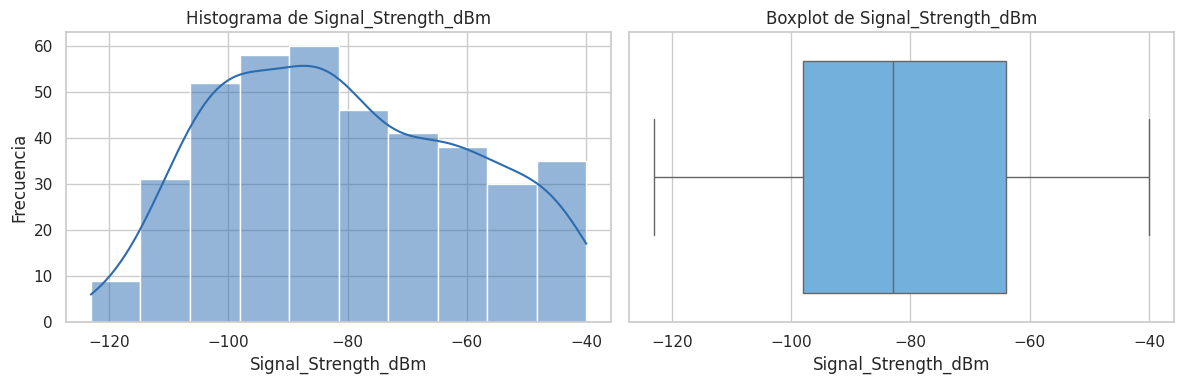

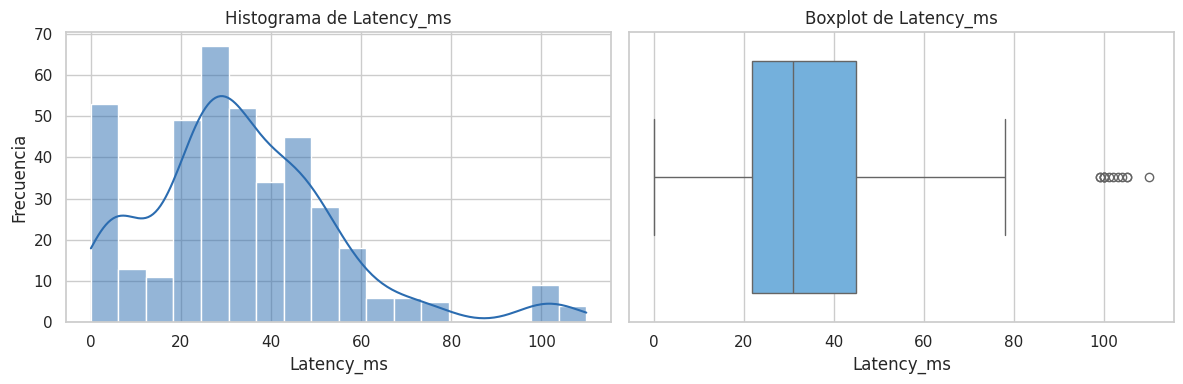

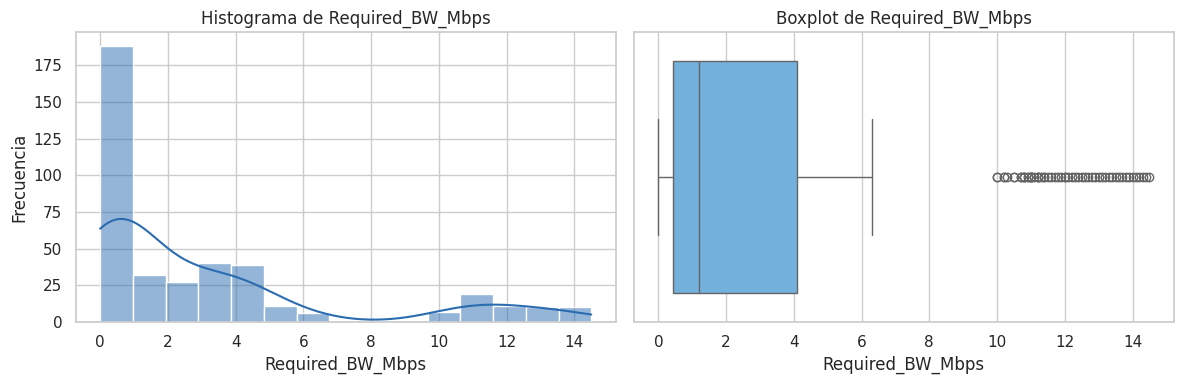

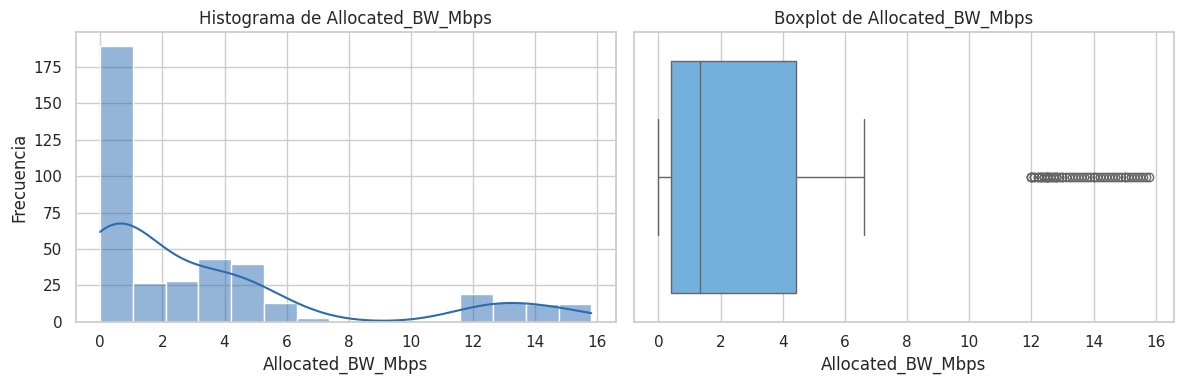

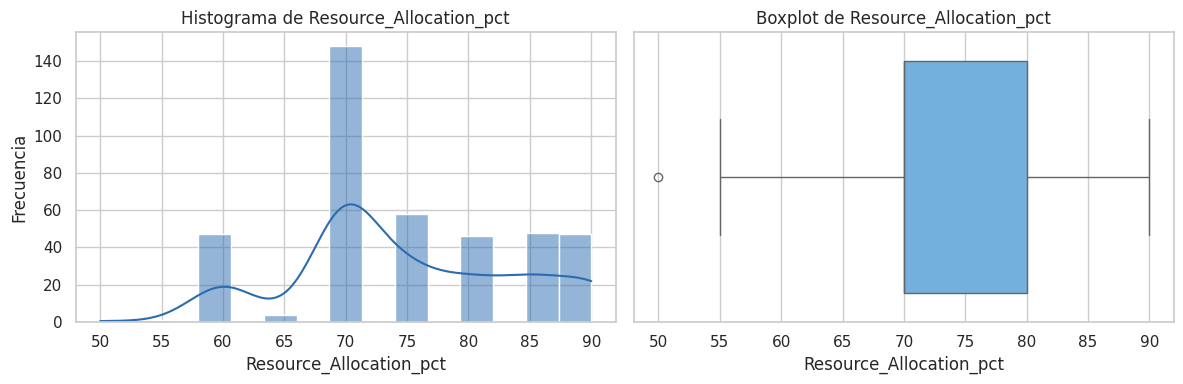

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in NUM:
  fig, axes = plt.subplots(1, 2, figsize=(12, 4))

  sns.histplot(data=df, x=col, kde=True, ax=axes[0], color="#2b6cb0")
  axes[0].set_title(f"Histograma de {col}")
  axes[0].set_xlabel(col)
  axes[0].set_ylabel("Frecuencia")

  sns.boxplot(data=df, x=col, ax=axes[1], color="#63b3ed")
  axes[1].set_title(f"Boxplot de {col}")
  axes[1].set_xlabel(col)

  plt.tight_layout()
  plt.show()

=== TABLA DE FRECUENCIAS: Application_Type ===


,Frecuencia_absoluta,Frecuencia_relativa_%
Application_Type,,
Video_Call,58,14.50
Web_Browsing,48,12.00
Background_Download,47,11.75
Video_Streaming,47,11.75
Emergency_Service,47,11.75
Streaming,47,11.75
VoIP_Call,46,11.50
Online_Gaming,45,11.25
IoT_Temperature,13,3.25


Moda de Application_Type: Video_Call

=== TABLA DE FRECUENCIAS: Nivel_Asignacion ===


,Frecuencia_absoluta,Frecuencia_relativa_%
Nivel_Asignacion,,
Media,206,51.50
Alta,141,35.25
Baja,53,13.25


Moda de Nivel_Asignacion: Media



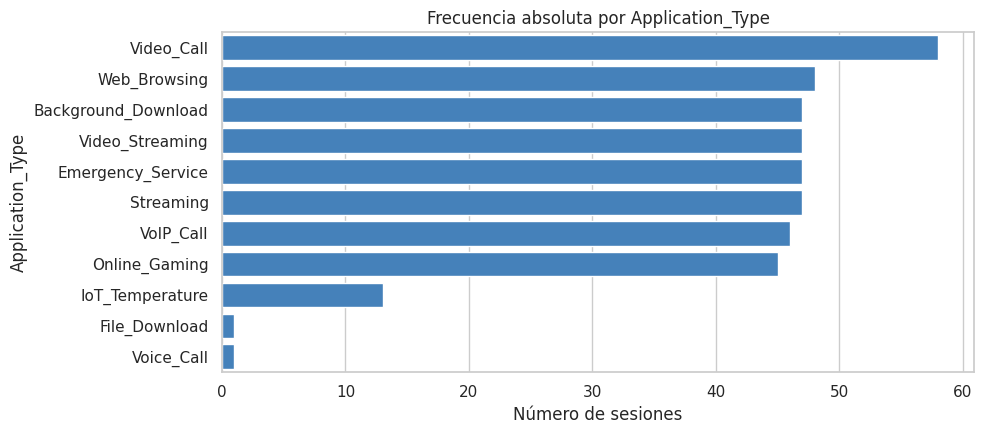

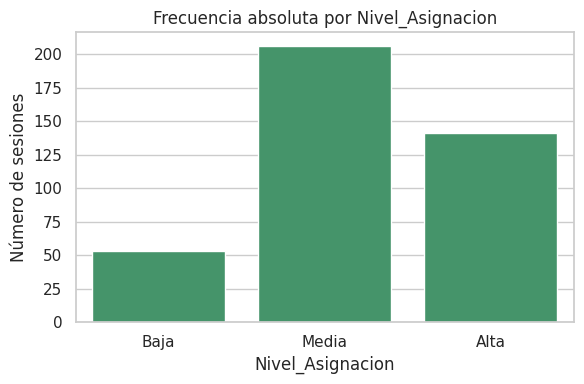

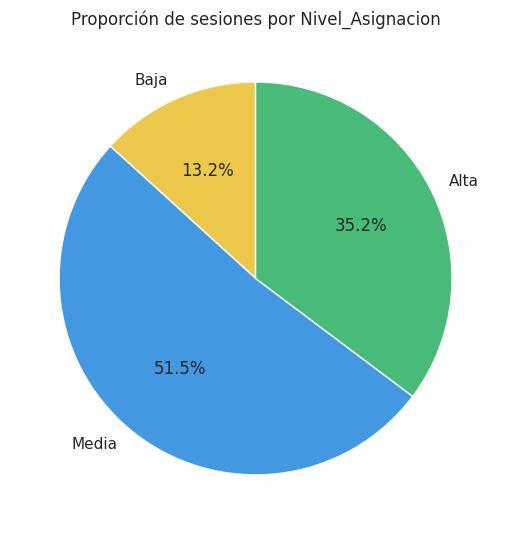

In [12]:
for col in ["Application_Type", "Nivel_Asignacion"]:
  abs_freq = df[col].value_counts()
  rel_freq = df[col].value_counts(normalize=True) * 100
  tabla_cat = pd.DataFrame({
      "Frecuencia_absoluta": abs_freq,
      "Frecuencia_relativa_%": rel_freq.round(2),
  })
  print(f"=== TABLA DE FRECUENCIAS: {col} ===")
  display(tabla_cat)
  print(f"Moda de {col}: {df[col].mode().iloc[0]}\n")

# Gráfico de barras: Application_Type
plt.figure(figsize=(10, 4.5))
orden_app = df["Application_Type"].value_counts().index
sns.countplot(data=df, y="Application_Type", order=orden_app, color="#3182ce")
plt.title("Frecuencia absoluta por Application_Type")
plt.xlabel("Número de sesiones")
plt.ylabel("Application_Type")
plt.tight_layout()
plt.show()

# Gráfico de barras: Nivel_Asignacion
plt.figure(figsize=(6, 4))
orden_nivel = ["Baja", "Media", "Alta"]
sns.countplot(
    data=df, x="Nivel_Asignacion", order=orden_nivel, color="#38a169"
)
plt.title("Frecuencia absoluta por Nivel_Asignacion")
plt.xlabel("Nivel_Asignacion")
plt.ylabel("Número de sesiones")
plt.tight_layout()
plt.show()

# Gráfico circular: Nivel_Asignacion
conteo_nivel = df["Nivel_Asignacion"].value_counts().reindex(orden_nivel)
plt.figure(figsize=(5.5, 5.5))
plt.pie(
    conteo_nivel,
    labels=conteo_nivel.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#ecc94b", "#4299e1", "#48bb78"],
)
plt.title("Proporción de sesiones por Nivel_Asignacion")
plt.tight_layout()
plt.show()

In [13]:
min_ts = df["Timestamp"].min()
max_ts = df["Timestamp"].max()
duracion_total = max_ts - min_ts
sesiones_por_minuto = df.groupby(df["Timestamp"].dt.floor("min"))[
    "User_ID"
].count()

print(f"Fecha/hora mínima: {min_ts}")
print(f"Fecha/hora máxima: {max_ts}")
print(f"Rango temporal cubierto: {duracion_total}")
print("\n=== SESIONES POR MINUTO ===")
display(sesiones_por_minuto.rename("Sesiones"))
print(
    f"Promedio de sesiones por minuto: {sesiones_por_minuto.mean():.2f} |"
    f" Mínimo: {sesiones_por_minuto.min()} | Máximo: {sesiones_por_minuto.max()}"
)

Fecha/hora mínima: 2023-09-03 10:00:00
Fecha/hora máxima: 2023-09-03 10:06:00
Rango temporal cubierto: 0 days 00:06:00

=== SESIONES POR MINUTO ===


,Sesiones
Timestamp,
2023-09-03 10:00:00,50
2023-09-03 10:01:00,60
2023-09-03 10:02:00,60
2023-09-03 10:03:00,60
2023-09-03 10:04:00,60
2023-09-03 10:05:00,60
2023-09-03 10:06:00,50


Promedio de sesiones por minuto: 57.14 | Mínimo: 50 | Máximo: 60


La función resumen_numerico reúne en una sola tabla métricas que describe, no muestra directamente, como la moda, el rango, la asimetría y la curtosis de exceso, manteniendo consistencia en media, desviación estándar, mínimo, cuartiles y máximo.
  
Para determinar la forma, tendencia central y dispersión observamos skew y kurt junto con los histogramas y boxplots, y determinamos si una distribución es aproximadamente positiva o negativa y si presenta colas más ligeras o pesadas que la normal. Cuando existe valores atípicos, la mediana resulta más representativa de la tendencia central que la media, mientras que en distribuciones simétricas sin outliers marcados ambas coinciden.

El análisis de Timestamp delimita la ventana de observación de las sesiones 5G y muestra la concentración o dispersión de tráfico por minuto.

FASE 6, ANÁLISIS BIVARIANTE

=== CORRELACIÓN DE PEARSON ===


,Signal_Strength_dBm,Latency_ms,Required_BW_Mbps,Allocated_BW_Mbps,Resource_Allocation_pct
Signal_Strength_dBm,1.0000,-0.3927,0.4614,0.4470,0.3036
Latency_ms,-0.3927,1.0000,0.0029,0.0033,-0.1378
Required_BW_Mbps,0.4614,0.0029,1.0000,0.9982,0.0724
Allocated_BW_Mbps,0.4470,0.0033,0.9982,1.0000,0.0767
Resource_Allocation_pct,0.3036,-0.1378,0.0724,0.0767,1.0000



=== CORRELACIÓN DE SPEARMAN ===


,Signal_Strength_dBm,Latency_ms,Required_BW_Mbps,Allocated_BW_Mbps,Resource_Allocation_pct
Signal_Strength_dBm,1.0000,-0.3487,0.4067,0.4122,0.3643
Latency_ms,-0.3487,1.0000,0.0693,0.0723,-0.0561
Required_BW_Mbps,0.4067,0.0693,1.0000,0.9990,0.1038
Allocated_BW_Mbps,0.4122,0.0723,0.9990,1.0000,0.1152
Resource_Allocation_pct,0.3643,-0.0561,0.1038,0.1152,1.0000


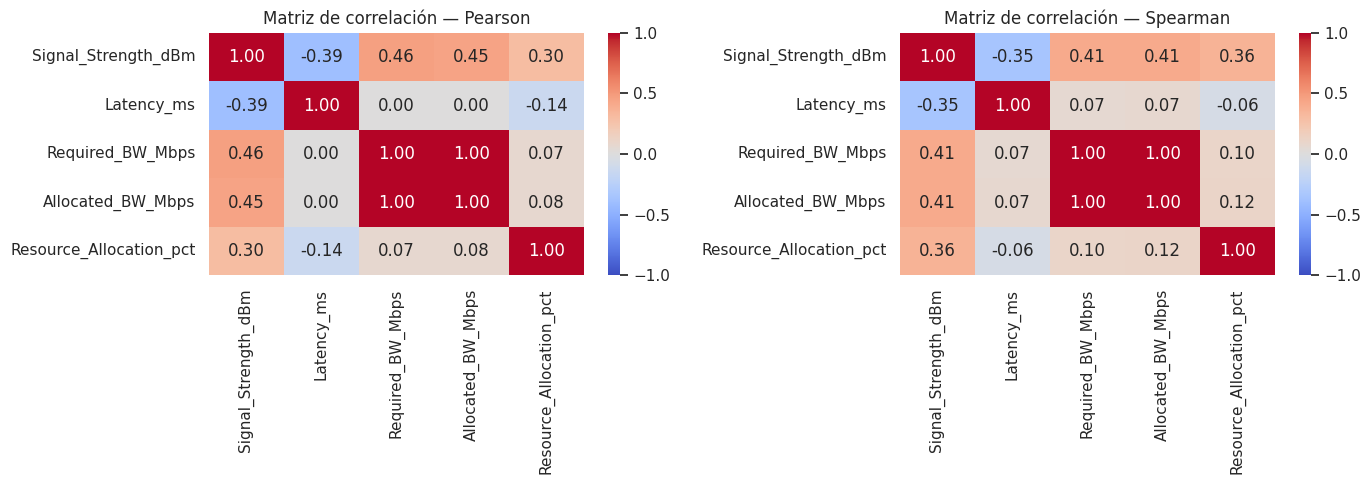

In [14]:
corr_pearson = df[NUM].corr(method="pearson")
corr_spearman = df[NUM].corr(method="spearman")

print("=== CORRELACIÓN DE PEARSON ===")
display(corr_pearson.round(4))

print("\n=== CORRELACIÓN DE SPEARMAN ===")
display(corr_spearman.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0],
)
axes[0].set_title("Matriz de correlación — Pearson")

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title("Matriz de correlación — Spearman")

plt.tight_layout()
plt.show()

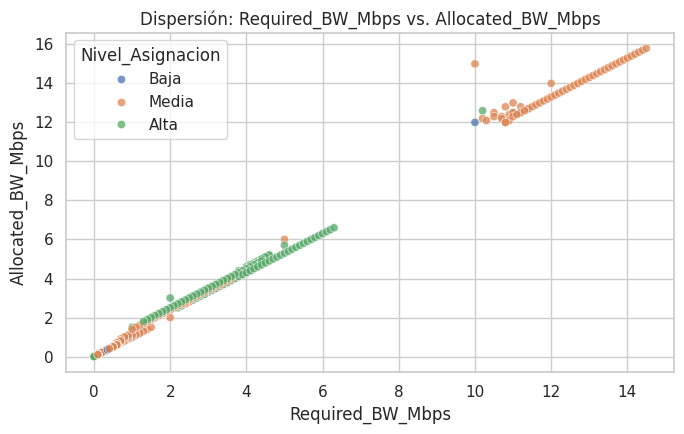

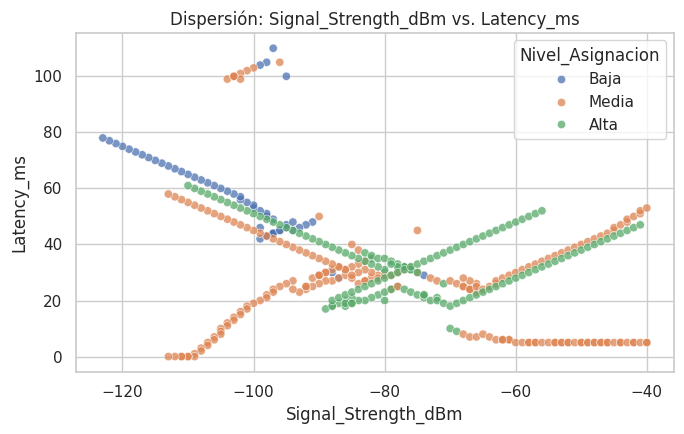

In [15]:
pares_dispersion = [
    ("Required_BW_Mbps", "Allocated_BW_Mbps"),
    ("Signal_Strength_dBm", "Latency_ms"),
]

for x_col, y_col in pares_dispersion:
  plt.figure(figsize=(7, 4.5))
  sns.scatterplot(
      data=df, x=x_col, y=y_col, hue="Nivel_Asignacion", alpha=0.75
  )
  plt.title(f"Dispersión: {x_col} vs. {y_col}")
  plt.xlabel(x_col)
  plt.ylabel(y_col)
  plt.tight_layout()
  plt.show()

=== RESUMEN NUMÉRICO POR Application_Type ===


Signal_Strength_dBm                 Latency_ms         \
                                   mean median      std       mean median   
Application_Type                                                            
Background_Download           -104.0638 -101.0   9.3887    56.9787   55.0   
Emergency_Service              -53.8298  -53.0   8.5295     5.5745    5.0   
File_Download                  -75.0000  -75.0      NaN    45.0000   45.0   
IoT_Temperature               -100.2308 -101.0   2.9764   102.1538  101.0   
Online_Gaming                  -62.1556  -63.0  12.0151    29.1111   25.0   
Streaming                      -89.6170  -87.0  10.6904    41.8511   39.0   
Video_Call                     -62.3966  -64.5  13.1268    32.8793   29.5   
Video_Streaming                -93.9362  -91.0   9.5403    38.8511   35.0   
VoIP_Call                      -75.7826  -78.5  10.2543    31.3043   29.5   
Voice_Call                     -80.0000  -80.0      NaN    20.0000   20.0   
Web_Browsing                   -99.7917 -101.0   8.0924    15.5625   17.5   

                             Required_BW_Mbps                   \
                         std             mean   median     std   
Application_Type                                                 
Background_Download  11.2723           0.5479   0.5700  0.1031   
Emergency_Service     1.1562           0.6787   0.6000  0.2105   
File_Download            NaN           2.0000   2.0000     NaN   
IoT_Temperature       3.1845           0.0038   0.0030  0.0031   
Online_Gaming         8.7001           4.1400   4.1000  1.2601   
Streaming             9.5165           3.3532   3.6000  1.0850   
Video_Call            8.8021          11.8147  11.7500  2.0268   
Video_Streaming       9.4477           2.9383   3.2000  0.9801   
VoIP_Call            11.1472           0.0816   0.0825  0.0591   
Voice_Call               NaN           0.1000   0.1000     NaN   
Web_Browsing         10.4044           0.4875   0.4000  0.4087   

                    Allocated_BW_Mbps                   \
                                 mean   median     std   
Application_Type                                         
Background_Download            0.5489   0.5700  0.1029   
Emergency_Service              0.7447   0.6000  0.2780   
File_Download                  2.0000   2.0000     NaN   
IoT_Temperature                0.0052   0.0040  0.0039   
Online_Gaming                  4.4556   4.4000  1.2372   
Streaming                      3.8936   4.1000  1.1338   
Video_Call                    13.2841  13.1500  2.1023   
Video_Streaming                3.3149   3.5000  0.9589   
VoIP_Call                      0.1041   0.1075  0.0620   
Voice_Call                     0.1200   0.1200     NaN   
Web_Browsing                   0.4875   0.4000  0.4087   

                    Resource_Allocation_pct                 
                                       mean median     std  
Application_Type                                            
Background_Download                 60.1064   60.0  1.6449  
Emergency_Service                   70.6383   70.0  3.2332  
File_Download                       70.0000   70.0     NaN  
IoT_Temperature                     70.3846   75.0  7.4893  
Online_Gaming                       80.0000   80.0  1.5076  
Streaming                           84.4681   85.0  2.6031  
Video_Call                          74.4828   75.0  3.4653  
Video_Streaming                     70.3191   70.0  1.6166  
VoIP_Call                           89.8913   90.0  0.7372  
Voice_Call                          80.0000   80.0     NaN  
Web_Browsing                        69.6875   70.0  1.6000


=== RESUMEN NUMÉRICO POR Nivel_Asignacion ===


Signal_Strength_dBm                 Latency_ms         \
                                mean median      std       mean median   
Nivel_Asignacion                                                         
Baja                       -102.6226  -99.0  10.1853    59.1321   56.0   
Media                       -77.9272  -83.0  22.2579    27.4612   27.0   
Alta                        -75.9291  -77.0  15.5341    33.6099   33.0   

                          Required_BW_Mbps                Allocated_BW_Mbps  \
                      std             mean median     std              mean   
Nivel_Asignacion                                                              
Baja              18.1235           0.7071   0.57  1.3177            0.7450   
Media             22.0637           4.1593   1.35  4.9297            4.6504   
Alta              11.6016           2.5525   2.80  2.2117            2.8616   

                                Resource_Allocation_pct                 
                 median     std                    mean median     std  
Nivel_Asignacion                                                        
Baja               0.57  1.5894                 60.0943   60.0  2.0779  
Media              1.55  5.5182                 71.4078   70.0  2.2543  
Alta               3.20  2.4400                 85.0355   85.0  4.0750

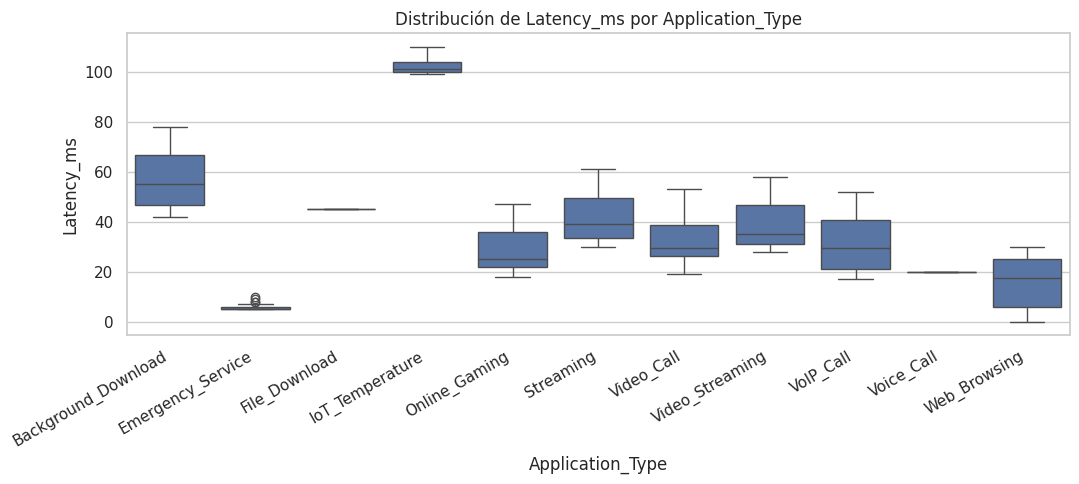

In [16]:
agg_app = df.groupby("Application_Type", observed=False)[NUM].agg(
    ["mean", "median", "std"]
)
print("=== RESUMEN NUMÉRICO POR Application_Type ===")
display(agg_app.round(4))

agg_nivel = df.groupby("Nivel_Asignacion", observed=False)[NUM].agg(
    ["mean", "median", "std"]
)
print("\n=== RESUMEN NUMÉRICO POR Nivel_Asignacion ===")
display(agg_nivel.round(4))

plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x="Application_Type", y="Latency_ms")
plt.title("Distribución de Latency_ms por Application_Type")
plt.xlabel("Application_Type")
plt.ylabel("Latency_ms")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [17]:
ct_abs = pd.crosstab(df["Application_Type"], df["Nivel_Asignacion"])
ct_prop = (
    pd.crosstab(df["Application_Type"], df["Nivel_Asignacion"], normalize="index")
    * 100
)

print("=== TABLA CRUZADA (FRECUENCIAS ABSOLUTAS) ===")
display(ct_abs)

print("\n=== TABLA CRUZADA (PROPORCIÓN POR FILA %) ===")
display(ct_prop.round(2))

=== TABLA CRUZADA (FRECUENCIAS ABSOLUTAS) ===


Nivel_Asignacion,Baja,Media,Alta
Application_Type,,,
Background_Download,46,1,0
Emergency_Service,0,45,2
File_Download,0,1,0
IoT_Temperature,4,9,0
Online_Gaming,0,2,43
Streaming,0,2,45
Video_Call,1,54,3
Video_Streaming,0,46,1
VoIP_Call,0,0,46



=== TABLA CRUZADA (PROPORCIÓN POR FILA %) ===


Nivel_Asignacion,Baja,Media,Alta
Application_Type,,,
Background_Download,97.87,2.13,0.00
Emergency_Service,0.00,95.74,4.26
File_Download,0.00,100.00,0.00
IoT_Temperature,30.77,69.23,0.00
Online_Gaming,0.00,4.44,95.56
Streaming,0.00,4.26,95.74
Video_Call,1.72,93.10,5.17
Video_Streaming,0.00,97.87,2.13
VoIP_Call,0.00,0.00,100.00


En las relaciones numéricas: Required_BW_Mbps y Allocated_BW_Mbps tienen correlación positiva casi perfecta 0.9982 en Pearson y 0.9990 en Spearman, mientras que Signal_Strength_dBm presenta correlación moderada con ancho de banda y asignación de recursos y negativa moderada con Latency_ms.

El Comportamiento por grupo y categoría: La latencia Latency_ms varía de forma marcada según Application_Type con valores muy bajos en Emergency_Service y muy altos en IoT_Temperature, y la tabla cruzada con Nivel_Asignacion muestra perfiles diferenciados: predominio de Baja en Background_Download 97.87%, de Media en Emergency_Service, Video_Call, Video_Streaming y Web_Browsing, y de Alta en Online_Gaming, Streaming y VoIP_Call.

FASE 7, ANÁLISIS DE CORRELACIÓN

=== MATRIZ DE CORRELACIÓN DE PEARSON (NUM) ===


,Signal_Strength_dBm,Latency_ms,Required_BW_Mbps,Allocated_BW_Mbps,Resource_Allocation_pct
Signal_Strength_dBm,1.0000,-0.3927,0.4614,0.4470,0.3036
Latency_ms,-0.3927,1.0000,0.0029,0.0033,-0.1378
Required_BW_Mbps,0.4614,0.0029,1.0000,0.9982,0.0724
Allocated_BW_Mbps,0.4470,0.0033,0.9982,1.0000,0.0767
Resource_Allocation_pct,0.3036,-0.1378,0.0724,0.0767,1.0000



=== CORRELACIÓN DE CADA VARIABLE CON Resource_Allocation_pct ===


,Pearson_vs_Resource_Allocation_pct,Spearman_vs_Resource_Allocation_pct
Signal_Strength_dBm,0.3036,0.3643
Latency_ms,-0.1378,-0.0561
Required_BW_Mbps,0.0724,0.1038
Allocated_BW_Mbps,0.0767,0.1152


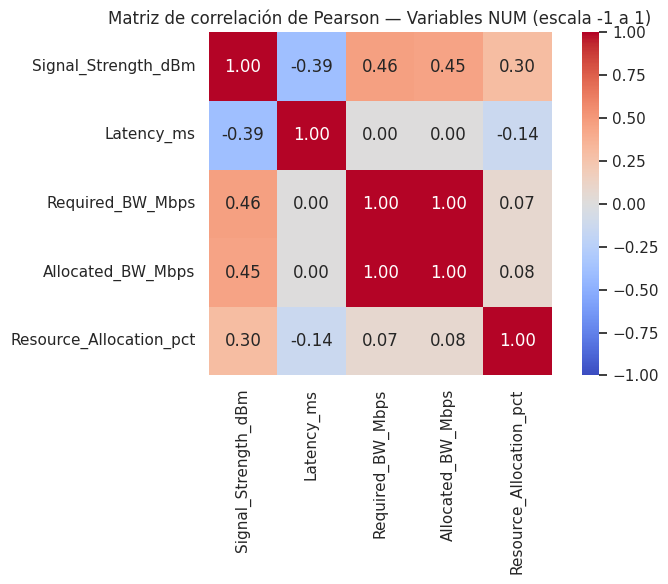

In [18]:
corr_pearson_7 = df[NUM].corr(method="pearson")
corr_spearman_7 = df[NUM].corr(method="spearman")

print("=== MATRIZ DE CORRELACIÓN DE PEARSON (NUM) ===")
display(corr_pearson_7.round(4))

corr_target = pd.DataFrame({
    "Pearson_vs_Resource_Allocation_pct": corr_pearson_7[
        "Resource_Allocation_pct"
    ],
    "Spearman_vs_Resource_Allocation_pct": corr_spearman_7[
        "Resource_Allocation_pct"
    ],
}).drop(index="Resource_Allocation_pct")

print("\n=== CORRELACIÓN DE CADA VARIABLE CON Resource_Allocation_pct ===")
display(corr_target.round(4))

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_pearson_7,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
)
plt.title("Matriz de correlación de Pearson — Variables NUM (escala -1 a 1)")
plt.tight_layout()
plt.show()

Los coeficientes de Pearson en el rango de -1 a 1 indican la dirección y fuerza de la relación lineal entre cada métrica y el porcentaje de recursos asignados.   

Redundancia y diferencia entre coeficientes: Si dos variables predictoras presentan una correlación alta entre sí, aportan información linealmente redundante. Asimismo, las diferencias en magnitud o signo entre coeficientes muestran cómo distintas variables se asocian con el objetivo o cómo relaciones no lineales pueden quedar subestimadas por PearsoN.

Una correlación elevada entre dos variables por ejemplo, entre ancho de banda y porcentaje de recursos asignados no prueba por sí sola que una cause a la otra; puede deberse a políticas de gestión de red, variables confusoras o coincidencia estadística en la muestra.

FASE 8, CONCLUSIONES

Calidad y estructura del dataset: El conjunto de datos Quality of Service 5G.csv cuenta con 400 registros y 8 columnas originales, sin valores nulos ni duplicados exactos, lo cual es un buen inicio para analizar sesiones de red 5G. Sin embargo, al revisar duplicados excluyendo User_ID y Timestamp aparecen 33 coincidencias, lo que puede reflejar reintentos, reportes repetidos o sesiones con parámetros similares en distintos instantes.

Comportamiento univariante y dinámica temporal: En el análisis individual, Signal_Strength_dBm tiene una media de -80.50 dBm y mediana de -83.00 dBm, mientras que Latency_ms media 33.83 ms, mediana 31.00 ms, Required_BW_Mbps media 3.14 Mbps, mediana 1.20 Mbps y Allocated_BW_Mbps media 3.50 Mbps, mediana 1.35 Mbps, presentan asimetría positiva con cola a la derecha, haciendo que la mediana sea más representativa que la media. Por su parte, Resource_Allocation_pct promedia 74.71% mediana 70.00%, en Nivel_Asignacion domina Media 51.5% sobre Alta 35.25% y Baja 13.25%, y el registro temporal abarca 6 minutos con un promedio de 57.14 sesiones por minuto, 50 al inicio y al cierre, y 60 entre 10:01 y 10:00.

Relaciones bivariantes y comportamiento por servicio: Se observa una relación lineal casi directa entre el ancho de banda requerido y el asignado, aunque con un salto de rango y perfiles distintos según el tipo de tráfico.

Variables más relacionadas con Resource_Allocation_pct: Evaluando la asociación con Resource_Allocation_pct, la variable numérica con relación moderada más clara es Signal_Strength_dBm, lo que sugiere que mejores condiciones de señal suelen acompañar porcentajes algo mayores de asignación. En cambio, Allocated_BW_Mbps, Required_BW_Mbps y Latency_ms muestran correlaciones lineales o de rango débiles frente al porcentaje asignado, lo que indica que la asignación porcentual responde a reglas de QoS y prioridades de servicio más que a una relación lineal simple con el throughput.

Redundancia, no linealidad y cautela causal: Incluir las variables Required_BW_Mbps como Allocated_BW_Mbps aporta información casi idéntica por su alta correlación, por lo que conviene evaluar redundancia o colinealidad al modelar. Asimismo, las diferencias entre Pearson y Spearman evidencian relaciones no lineales o escalonadas en métricas de red, y recordar que correlación no implica causalidad es clave en telecomunicaciones: una mayor o menor asignación o latencia no se explica por una sola variable aislada sin considerar políticas de planificación de radio, carga de red y prioridad de la aplicación.

